# Phase 1 Task B — MobileNetV3-Large × 3 Seeds

**Model:** MobileNetV3-Large
**Seeds:** 42, 123, 456
**Batch:** 64
**Output:** wandb `woodbench-taskB`

Chạy notebook này trên 1 GPU (vast.ai).

In [1]:
from pathlib import Path
NOTEBOOK = Path("__file__").resolve()
ROOT = NOTEBOOK
for _ in range(10):
    ROOT = ROOT.parent
    if (ROOT / "pyproject.toml").exists() or (ROOT / ".git").exists(): break
import sys, os
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
print(f"[ROOT] {ROOT}")

[ROOT] /workspace/woodbench


In [2]:
from dotenv import load_dotenv
load_dotenv(dotenv_path := ROOT / ".env")
print(f"[.env] Loaded from {dotenv_path}")

import subprocess, sys
for pkg in ["timm", "albumentations", "scikit-learn", "seaborn", "wandb", "ptflops"]:
    try: __import__(pkg.replace("-", "_"))
    except: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

os.environ.setdefault("WANDB_API_KEY", os.getenv("WANDB_API_KEY", ""))
print(f"[wandb] API key: {'set' if os.getenv('WANDB_API_KEY') else 'MISSING'}")

python-dotenv could not parse statement starting at line 4
python-dotenv could not parse statement starting at line 6
python-dotenv could not parse statement starting at line 7


[.env] Loaded from /workspace/woodbench/.env


[wandb] API key: set


In [3]:
from src.data import get_dataloaders
DATA_ROOT = ROOT / "data" / "task-B"
tl, vl, testl = get_dataloaders(str(DATA_ROOT), batch_size=64, num_workers=4, task="taskB")
print(f"[Data] Train={len(tl.dataset)}, Val={len(vl.dataset)}, Test={len(testl.dataset)}")
print(f"[Data] Classes={len(tl.dataset.classes)}")

[Data] Train=3973, Val=933, Test=924
[Data] Classes=20


In [4]:
import wandb, torch, numpy as np
from src.models import create_model
from src.train import TrainingEngine, create_optimizer, create_scheduler, create_loss_function
from src.utils import set_seed

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"[Device] {DEVICE}")

[Device] cuda


In [5]:
def train_one(backbone, seed, data_root, batch_size=64, epochs=50):
    set_seed(seed)
    output_dir = ROOT / "data" / "experiments" / "taskB" / backbone / f"seed_{seed}"
    output_dir.mkdir(parents=True, exist_ok=True)

    train_loader, val_loader, _ = get_dataloaders(
        data_root=data_root, batch_size=batch_size, num_workers=4, task="taskB"
    )
    num_classes = len(train_loader.dataset.classes)
    print(
        f"[{backbone} s{seed}] train={len(train_loader.dataset)}, classes={num_classes}"
    )

    run = wandb.init(
        project="woodbench-taskB",
        name=f"{backbone}_s{seed}",
        config={
            "backbone": backbone,
            "seed": seed,
            "epochs": epochs,
            "batch_size": batch_size,
            "num_classes": num_classes,
            "lr_head": 1e-4,
            "lr_backbone": 1e-5,
            "label_smoothing": 0.1,
            "scheduler": "cosine",
            "amp": True,
        },
        dir=str(output_dir),
    )

    model = create_model(backbone, num_classes=num_classes, pretrained=True)
    optimizer = create_optimizer(model, lr=1e-4, weight_decay=1e-4, backbone_lr=1e-5)
    scheduler = create_scheduler(optimizer, epochs=epochs, scheduler_type="cosine")
    criterion = create_loss_function("label_smoothing", label_smoothing=0.1)

    engine = TrainingEngine(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        device=DEVICE,
        use_amp=True,
    )
    result = engine.fit(
        epochs=epochs,
        output_dir=output_dir,
        name=f"{backbone}_seed{seed}",
        save_best_only=True,
        early_stopping_patience=10,
    )
    run.finish()
    print(f"[{backbone} s{seed}] val_acc={result['best_val_acc']:.2f}%")
    return result

In [6]:
SEEDS = [42, 123, 456]
results = {}

for seed in SEEDS:
    print(f"\n{'='*60}")
    print(f"MobileNetV3-Large | seed={seed} ({SEEDS.index(seed)+1}/{len(SEEDS)})")
    print(f"{'='*60}")
    results[seed] = train_one("mobilenetv3_large", seed, str(DATA_ROOT), batch_size=64, epochs=50)

print("\n" + "="*60)
print("MobileNetV3-Large — Summary")
for seed, res in results.items():
    print(f"  seed={seed}: {res['best_val_acc']:.2f}%")
accs = [r['best_val_acc'] for r in results.values()]
print(f"  Mean: {np.mean(accs):.2f}% ± {np.std(accs):.2f}%")


MobileNetV3-Large | seed=42 (1/3)


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: ny0g507h3p (ny0g507h3p_) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


[mobilenetv3_large s42] train=3973, classes=20


Epoch 1/50 | Train Loss: 2.9978, Acc: 7.03% | Val Loss: 2.9855, Acc: 6.11% | LR: 2.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to mobilenetv3_large_seed42_best.pth (Val Acc: 6.11%)


Epoch 2/50 | Train Loss: 2.8761, Acc: 19.96% | Val Loss: 2.7849, Acc: 26.37% | LR: 4.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to mobilenetv3_large_seed42_best.pth (Val Acc: 26.37%)


Epoch 3/50 | Train Loss: 2.5123, Acc: 51.97% | Val Loss: 2.3472, Acc: 54.88% | LR: 6.00e-05[Best][EarlyStop 0/10]
  ↳ New best! Saved to mobilenetv3_large_seed42_best.pth (Val Acc: 54.88%)


... (136 outputs left out)

Epoch 48/50 | Train Loss: 0.6671, Acc: 99.37% | Val Loss: 0.6805, Acc: 99.46% | LR: 4.87e-07[EarlyStop 2/10]


Epoch 49/50 | Train Loss: 0.6657, Acc: 99.34% | Val Loss: 0.6828, Acc: 99.57% | LR: 1.22e-07[EarlyStop 3/10]


Epoch 50/50 | Train Loss: 0.6636, Acc: 99.34% | Val Loss: 0.6824, Acc: 99.46% | LR: 0.00e+00[EarlyStop 4/10]


[mobilenetv3_large s456] val_acc=99.68%

MobileNetV3-Large — Summary
  seed=42: 99.57%
  seed=123: 99.79%
  seed=456: 99.68%
  Mean: 99.68% ± 0.09%


[CM] 20 classes
[CM] Loading: /workspace/woodbench/data/experiments/taskB/mobilenetv3_large/seed_42/mobilenetv3_large_seed42_best.pth
[CM s42] Acc=98.48%  F1=98.48%  Prec=98.56%  Rec=98.48%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=98.08%
  Calocedrus rupestris: F1=100.00%
  Calocedrus sp: F1=100.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=97.96%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=98.90%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=96.15%
  Pinus krempfii: F1=97.92%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=100.00%
  Podocarpus pilgeri: F1=97.83%
  Pseudotsuga brevifolia: F1=97.73%
  Taxus wallichiana: F1=90.24%
  Thujopsis dolabrata: F1=98.99%
  Xanthocyparis vietnamensis: F1=95.83%


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/taskB/mobilenetv3_large/seed_123/mobilenetv3_large_seed123_best.pth
[CM s123] Acc=98.59%  F1=98.56%  Prec=98.57%  Rec=98.60%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=98.04%
  Calocedrus rupestris: F1=98.88%
  Calocedrus sp: F1=98.59%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=98.99%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=97.83%
  Pinus cernua: F1=98.85%
  Pinus dalatensis: F1=99.01%
  Pinus krempfii: F1=98.97%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=100.00%
  Podocarpus pilgeri: F1=96.77%
  Pseudotsuga brevifolia: F1=96.63%
  Taxus wallichiana: F1=92.86%
  Thujopsis dolabrata: F1=97.96%
  Xanthocyparis vietnamensis: F1=97.87%


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Loading: /workspace/woodbench/data/experiments/taskB/mobilenetv3_large/seed_456/mobilenetv3_large_seed456_best.pth
[CM s456] Acc=98.81%  F1=98.79%  Prec=98.83%  Rec=98.81%
  Araucaria araucana: F1=100.00%
  Callitris columellaris: F1=100.00%
  Calocedrus rupestris: F1=98.88%
  Calocedrus sp: F1=100.00%
  Chamaecyparis obtusa: F1=100.00%
  Cryptomeria japonica: F1=100.00%
  Cunninghamia lanceolata: F1=98.99%
  Cupressus funebris (Cupressus pendula): F1=100.00%
  Fokienia hodginsii: F1=100.00%
  Picea glauca: F1=97.83%
  Pinus cernua: F1=100.00%
  Pinus dalatensis: F1=98.04%
  Pinus krempfii: F1=97.92%
  Pinus radiata: F1=100.00%
  Pinus sp: F1=100.00%
  Podocarpus pilgeri: F1=97.83%
  Pseudotsuga brevifolia: F1=96.63%
  Taxus wallichiana: F1=92.86%
  Thujopsis dolabrata: F1=97.96%
  Xanthocyparis vietnamensis: F1=98.97%


test/accuracy,▁
test/f1,▁
test/f1/Araucaria araucana,▁
test/f1/Callitris columellaris,▁
test/f1/Calocedrus rupestris,▁
test/f1/Calocedrus sp,▁
test/f1/Chamaecyparis obtusa,▁
test/f1/Cryptomeria japonica,▁
test/f1/Cunninghamia lanceolata,▁
test/f1/Cupressus funebris (Cupressus pendula),▁
+14,...


[CM] Saved to /workspace/woodbench/data/experiments/taskB/mobilenetv3_large/confusion_matrix.png


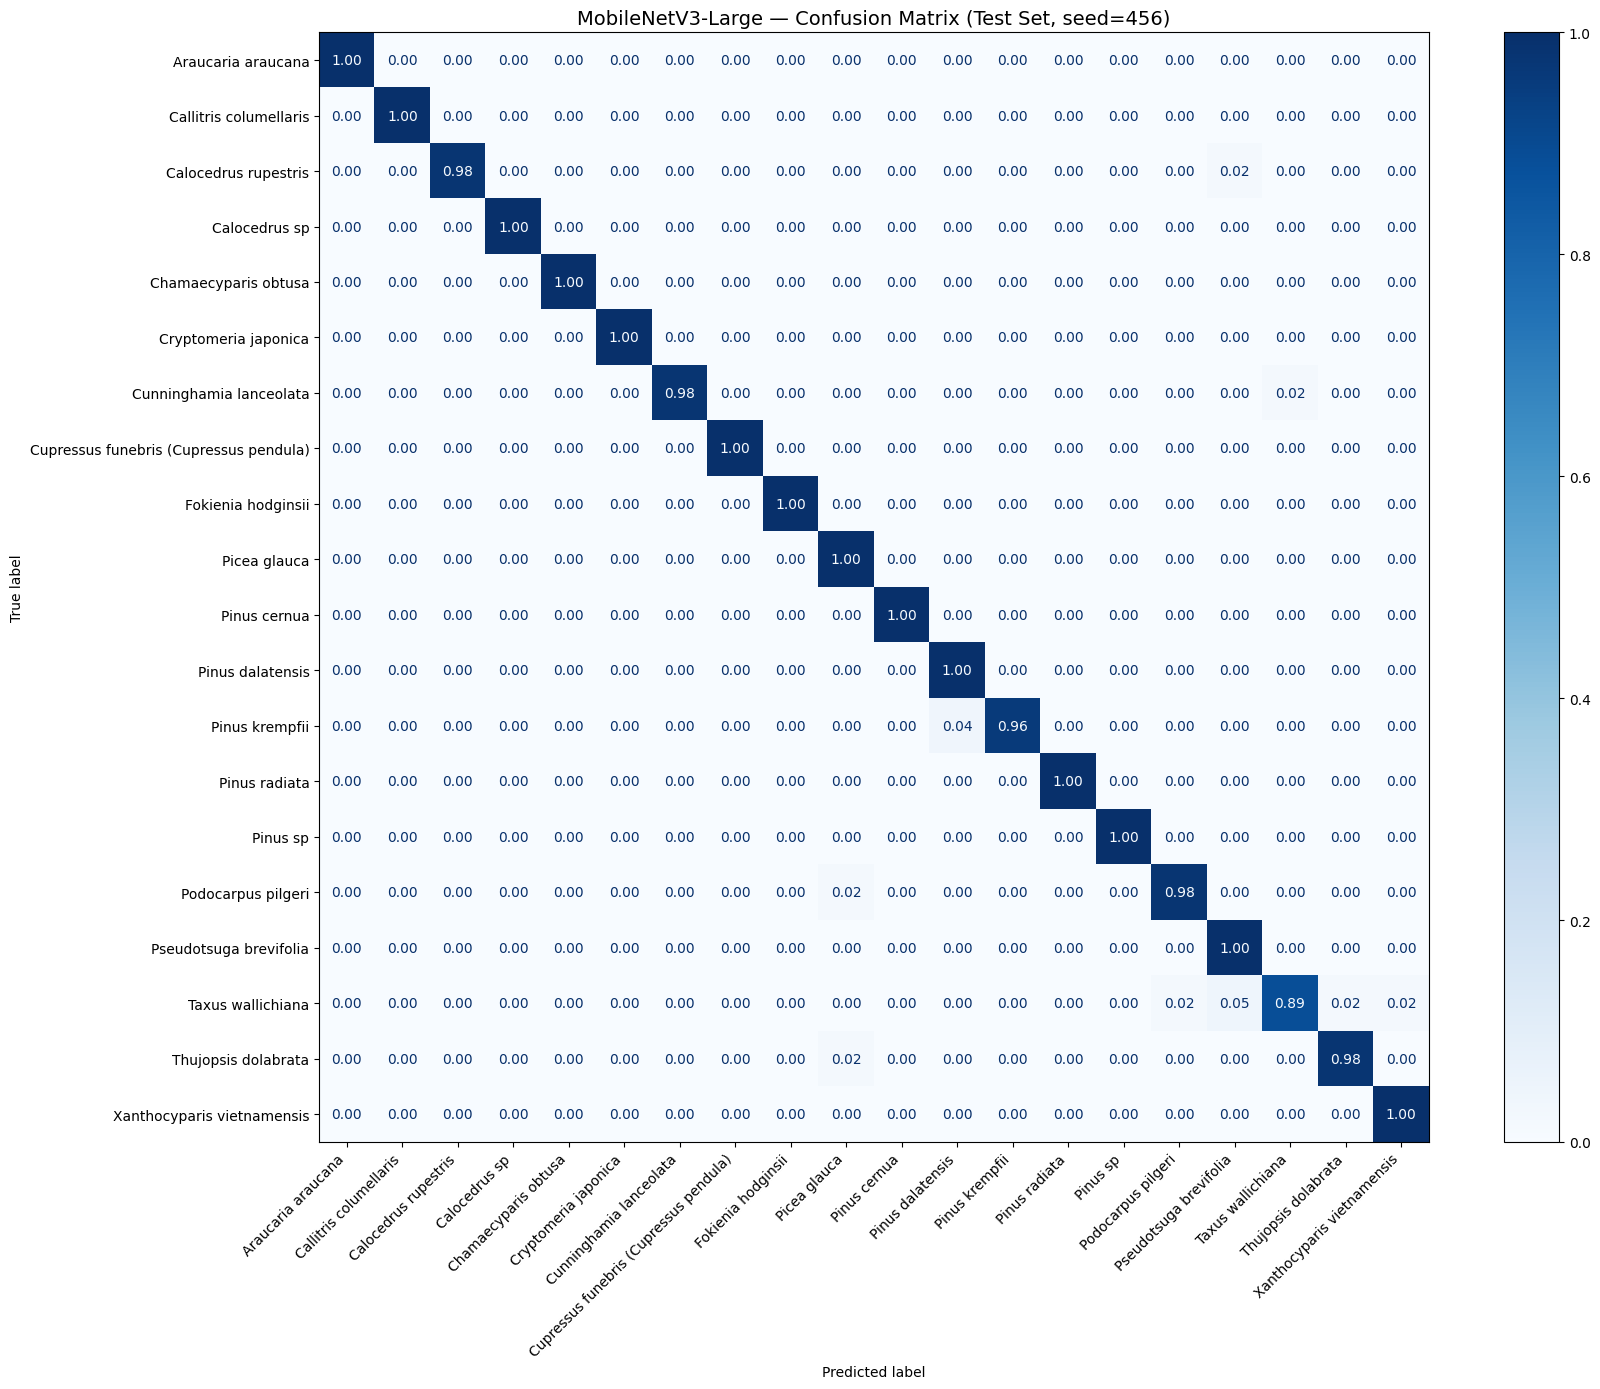


Classification Report (best seed = 456 )
                                        precision    recall  f1-score   support

                    Araucaria araucana       1.00      1.00      1.00        45
                Callitris columellaris       1.00      1.00      1.00        51
                  Calocedrus rupestris       1.00      0.98      0.99        45
                         Calocedrus sp       1.00      1.00      1.00        35
                  Chamaecyparis obtusa       1.00      1.00      1.00        48
                  Cryptomeria japonica       1.00      1.00      1.00        51
               Cunninghamia lanceolata       1.00      0.98      0.99        50
Cupressus funebris (Cupressus pendula)       1.00      1.00      1.00        48
                    Fokienia hodginsii       1.00      1.00      1.00        52
                          Picea glauca       0.96      1.00      0.98        45
                          Pinus cernua       1.00      1.00      1.00        

In [7]:
# ── Cell 7: Confusion Matrix + Test Metrics (all seeds) ──────────────────────
import torch, numpy as np, matplotlib.pyplot as plt, wandb
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from src.data import get_dataloaders
DATA_ROOT = ROOT / "data" / "task-B"
_ignored_train, _ignored_val, test_loader = get_dataloaders(
    str(DATA_ROOT), batch_size=64, num_workers=4, task="taskB")
class_names = test_loader.dataset.classes
num_classes = len(class_names)
print(f"[CM] {num_classes} classes")

SEEDS = [42, 123, 456]
all_preds, all_labels = {}, {}

for seed in SEEDS:
    backbone_dir = ROOT / "data" / "experiments"  / "taskB" / "mobilenetv3_large" / f"seed_{seed}"
    ckpt_candidates = sorted(backbone_dir.glob("*best*.pth"))
    if not ckpt_candidates:
        print(f"[CM] No checkpoint found for seed={seed}, skipping"); continue
    ckpt_path = ckpt_candidates[0]
    print(f"[CM] Loading: {ckpt_path}")

    from src.models import create_model
    model = create_model("mobilenetv3_large", num_classes=num_classes, pretrained=False)
    ckpt = torch.load(ckpt_path, map_location="cpu")
    model.load_state_dict(ckpt["model_state_dict"])
    model = model.to(DEVICE).eval()

    preds_s, labels_s = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            outputs = model(images)
            preds_s.extend(outputs.argmax(1).cpu().numpy())
            labels_s.extend(labels.numpy())
    all_preds[seed] = np.array(preds_s)
    all_labels[seed] = np.array(labels_s)

    from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
    acc = accuracy_score(labels_s, preds_s)
    f1  = f1_score(labels_s, preds_s, average="macro", zero_division=0)
    prec = precision_score(labels_s, preds_s, average="macro", zero_division=0)
    rec  = recall_score(labels_s, preds_s, average="macro", zero_division=0)
    f1_per = f1_score(labels_s, preds_s, average=None, zero_division=0)
    print(f"[CM s{seed}] Acc={acc*100:.2f}%  F1={f1*100:.2f}%  Prec={prec*100:.2f}%  Rec={rec*100:.2f}%")
    for cn, fi in zip(class_names, f1_per):
        print(f"  {cn}: F1={fi*100:.2f}%")

    wandb.init(project="woodbench-taskB", name=f"mobilenetv3_large_s{seed}_test",
               dir=str(backbone_dir))
    wandb.log({"test/accuracy": acc, "test/precision": prec, "test/recall": rec, "test/f1": f1,
               **{f"test/f1/{cn}": float(fi) for cn, fi in zip(class_names, f1_per)}})
    wandb.finish()

if not all_preds:
    raise RuntimeError("No checkpoints found — cannot plot confusion matrix")

best_seed = max(all_preds, key=lambda s: accuracy_score(all_labels[s], all_preds[s]))
y_true, y_pred = all_labels[best_seed], all_preds[best_seed]
fig, ax = plt.subplots(figsize=(18, 14))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names,
    cmap="Blues", normalize="true", ax=ax, values_format=".2f")
ax.set_title(f"MobileNetV3-Large — Confusion Matrix (Test Set, seed={best_seed})", fontsize=14)
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
cm_path = ROOT / "data" / "experiments"  / "taskB" / "mobilenetv3_large" / "confusion_matrix.png"
fig.savefig(cm_path, dpi=150, bbox_inches="tight")
print(f"[CM] Saved to {cm_path}")
wandb.init(project="woodbench-taskB", name="mobilenetv3_large_CM",
           dir=str(ROOT / "data" / "experiments"  / "taskB" / "mobilenetv3_large"))
wandb.log({"confusion_matrix": wandb.Image(str(cm_path))}); wandb.finish(); plt.show()
print("\n" + "="*80)
print("Classification Report (best seed =", best_seed, ")")
print("="*80)
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))